<a href="https://colab.research.google.com/github/9c12manasvip-code/PHM-AI-reg-no-29-36-/blob/main/Smart_ATM_Tamper_Detection_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart ATM Skimming & Physical Tamper Detection System

In [ ]:
# 1. Import libraries and set reproducible random seed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    balanced_accuracy_score, matthews_corrcoef
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print("Smart ATM Tamper Detection — demonstration initialized")
print("Data source: simulated MPU6050-like sensor readings")
print("Sampling rate: 100 Hz | Window size: 1 second")


Smart ATM Tamper Detection — demonstration initialized
Data source: simulated MPU6050-like sensor readings
Sampling rate: 100 Hz | Window size: 1 second


In [ ]:
# 2. Generate synthetic sensor readings
# Labels: 0 = normal, 1 = suspicious/tamper activity
FS = 100
SECONDS_NORMAL = 12 * 60
SECONDS_ATTACK = 5 * 60

def make_segment(seconds, label, mode="normal", start_time=0):
    n = seconds * FS
    t = np.arange(n) / FS + start_time

    # Approximate gravity on Z axis, small normal sensor noise
    ax = rng.normal(0, 0.035, n)
    ay = rng.normal(0, 0.035, n)
    az = 1.0 + rng.normal(0, 0.035, n)
    gx = rng.normal(0, 0.7, n)
    gy = rng.normal(0, 0.7, n)
    gz = rng.normal(0, 0.7, n)

    if mode == "normal":
        # Mild keypad/door/movement-like events at scattered times
        for _ in range(max(1, seconds // 25)):
            center = rng.integers(0, n)
            width = int(rng.integers(3, 12))
            lo, hi = max(0, center-width), min(n, center+width)
            pulse = np.exp(-np.linspace(-2, 2, hi-lo)**2)
            ax[lo:hi] += 0.10 * pulse
            ay[lo:hi] += 0.08 * pulse
            gx[lo:hi] += 1.8 * pulse
    else:
        # Stronger vibration bursts representing simulated attack patterns
        for _ in range(max(4, seconds // 8)):
            center = rng.integers(0, n)
            width = int(rng.integers(8, 35))
            lo, hi = max(0, center-width), min(n, center+width)
            idx = np.arange(hi-lo)
            pulse = np.sin(2*np.pi*idx/rng.integers(4, 13)) * np.hanning(max(hi-lo, 3))[:hi-lo]
            severity = {"shaking": 0.7, "hitting": 1.1, "prying": 0.9, "drilling": 0.55}.get(mode, 0.8)
            ax[lo:hi] += severity * pulse
            ay[lo:hi] += 0.8 * severity * pulse
            az[lo:hi] += 0.7 * severity * pulse
            gx[lo:hi] += 10 * severity * pulse
            gy[lo:hi] += 8 * severity * pulse
            gz[lo:hi] += 6 * severity * pulse

    return pd.DataFrame({
        "timestamp_s": t, "ax": ax, "ay": ay, "az": az,
        "gx": gx, "gy": gy, "gz": gz,
        "label": np.full(n, label, dtype=int),
        "activity": np.full(n, mode, dtype=object)
    })

normal_df = make_segment(SECONDS_NORMAL, 0, "normal", 0)
attack_df = make_segment(SECONDS_ATTACK, 1, "shaking", SECONDS_NORMAL)
raw_df = pd.concat([normal_df, attack_df], ignore_index=True)

print(f"Generated {len(raw_df):,} simulated sensor samples.")
print(f"Normal samples: {(raw_df.label == 0).sum():,}")
print(f"Suspicious samples: {(raw_df.label == 1).sum():,}")
display(raw_df.head(10).round(4))


Generated 102,000 simulated sensor samples.
Normal samples: 72,000
Suspicious samples: 30,000


,timestamp_s,ax,ay,az,gx,gy,gz,label,activity
0,0.00,0.0107,-0.0338,0.9687,-0.6671,1.6412,0.8449,0,normal
1,0.01,-0.0364,-0.0315,1.0172,0.5760,-0.4400,-0.4426,0,normal
2,0.02,0.0263,0.0179,0.9482,0.6001,-0.7232,-0.3537,0,normal
3,0.03,0.0329,0.0256,0.9703,0.4366,-0.3149,0.4472,0,normal
4,0.04,-0.0683,0.0607,1.0028,-0.3472,0.4333,0.7383,0,normal
5,0.05,-0.0456,-0.0329,0.9985,0.2774,0.9467,-0.7329,0,normal
6,0.06,0.0045,0.0616,0.9827,0.2669,-0.1198,1.8185,0,normal
7,0.07,-0.0111,-0.0091,0.9693,-1.0644,0.4675,-1.1581,0,normal
8,0.08,-0.0006,0.0028,0.9685,-0.2659,0.5850,-1.1574,0,normal
9,0.09,-0.0299,-0.0041,1.0213,0.1598,0.7415,-0.3811,0,normal


In [ ]:
# 3. Convert 100 Hz sensor readings into 1-second window features
SENSOR_COLS = ["ax", "ay", "az", "gx", "gy", "gz"]

def dominant_frequency(values, fs=FS):
    values = np.asarray(values, dtype=float)
    values = values - values.mean()
    spectrum = np.abs(np.fft.rfft(values))
    freqs = np.fft.rfftfreq(len(values), d=1/fs)
    if len(spectrum) <= 1:
        return 0.0
    spectrum[0] = 0
    return float(freqs[np.argmax(spectrum)])

feature_rows = []
for window_id, start in enumerate(range(0, len(raw_df), FS)):
    chunk = raw_df.iloc[start:start+FS]
    if len(chunk) < FS:
        continue
    row = {
        "window_id": window_id,
        "timestamp_s": float(chunk["timestamp_s"].iloc[0]),
        "label": int(chunk["label"].max()),
        "activity": str(chunk["activity"].iloc[0]),
    }
    for col in SENSOR_COLS:
        vals = chunk[col].to_numpy()
        row[f"{col}_mean"] = float(np.mean(vals))
        row[f"{col}_std"] = float(np.std(vals))
        row[f"{col}_peak"] = float(np.max(np.abs(vals)))
    row["accel_dominant_freq_hz"] = dominant_frequency(
        np.sqrt(chunk["ax"].to_numpy()**2 +
                chunk["ay"].to_numpy()**2 +
                chunk["az"].to_numpy()**2), FS)
    row["gyro_dominant_freq_hz"] = dominant_frequency(
        np.sqrt(chunk["gx"].to_numpy()**2 +
                chunk["gy"].to_numpy()**2 +
                chunk["gz"].to_numpy()**2), FS)
    feature_rows.append(row)

features_df = pd.DataFrame(feature_rows)
feature_cols = [c for c in features_df.columns
                if c not in ["window_id", "timestamp_s", "label", "activity"]]

print("Feature extraction completed.")
print("Features per window:", len(feature_cols))
display(features_df.head(8).round(4))


Feature extraction completed.
Features per window: 20


,window_id,timestamp_s,label,activity,ax_mean,ax_std,ax_peak,ay_mean,ay_std,ay_peak,...,gx_std,gx_peak,gy_mean,gy_std,gy_peak,gz_mean,gz_std,gz_peak,accel_dominant_freq_hz,gyro_dominant_freq_hz
0,0,0.0,0,normal,-0.0018,0.0270,0.0750,-0.0079,0.0338,0.0931,...,0.7178,1.8357,-0.0502,0.6518,1.7506,-0.0240,0.6354,1.8185,29.0,39.0
1,1,1.0,0,normal,-0.0004,0.0341,0.1020,0.0021,0.0354,0.0828,...,0.7306,1.7571,0.0773,0.7039,2.0448,0.0839,0.6673,1.9737,29.0,15.0
2,2,2.0,0,normal,-0.0022,0.0357,0.1017,-0.0051,0.0367,0.1194,...,0.6842,2.2433,-0.0078,0.6865,1.9294,0.0073,0.6569,1.9137,35.0,4.0
3,3,3.0,0,normal,0.0036,0.0353,0.0815,-0.0006,0.0349,0.0929,...,0.7172,2.1709,-0.0403,0.6786,2.2774,-0.0102,0.6013,1.5832,31.0,46.0
4,4,4.0,0,normal,-0.0016,0.0346,0.0909,0.0015,0.0344,0.0948,...,0.7420,2.1361,0.0259,0.7735,2.6142,0.0274,0.6834,1.7157,12.0,8.0
5,5,5.0,0,normal,-0.0032,0.0363,0.1038,-0.0018,0.0344,0.0890,...,0.7410,1.8967,0.0151,0.5726,1.9495,-0.0564,0.7056,1.6193,42.0,11.0
6,6,6.0,0,normal,-0.0039,0.0364,0.0898,0.0032,0.0359,0.0889,...,0.6997,2.4034,-0.0461,0.6562,1.5546,-0.1437,0.6396,2.1329,10.0,3.0
7,7,7.0,0,normal,0.0013,0.0344,0.0798,-0.0035,0.0374,0.1183,...,0.6944,1.6265,-0.0076,0.6785,1.8623,0.0964,0.7625,2.3560,37.0,18.0


In [ ]:
# 4. Train/test split by time; train Isolation Forest on normal training windows only
# First 70% of normal windows are used for training.
normal_features = features_df[features_df.label == 0].copy()
attack_features = features_df[features_df.label == 1].copy()

split_at = int(len(normal_features) * 0.70)
train_normal = normal_features.iloc[:split_at]
test_normal = normal_features.iloc[split_at:]

# Test contains held-out normal windows and all simulated attack windows.
test_df = pd.concat([test_normal, attack_features], ignore_index=True)
X_train = train_normal[feature_cols]
X_test = test_df[feature_cols]
y_test = test_df["label"].to_numpy()

model = IsolationForest(
    n_estimators=200,
    contamination=0.12,
    random_state=RANDOM_STATE
)
model.fit(X_train)

# Isolation Forest returns +1 for inliers and -1 for outliers.
test_df = test_df.copy()
test_df["anomaly_score"] = -model.decision_function(X_test)
test_df["predicted_label"] = (model.predict(X_test) == -1).astype(int)

print("Model training completed.")
print("Algorithm: Isolation Forest")
print(f"Training windows (normal only): {len(X_train):,}")
print(f"Test windows: {len(X_test):,}")
print("Prediction rule: 0 = normal, 1 = anomaly/suspicious")
display(test_df[["timestamp_s", "activity", "label", "predicted_label", "anomaly_score"]].head(12).round(4))


Model training completed.
Algorithm: Isolation Forest
Training windows (normal only): 503
Test windows: 517
Prediction rule: 0 = normal, 1 = anomaly/suspicious


,timestamp_s,activity,label,predicted_label,anomaly_score
0,503.0,normal,0,0,-0.0423
1,504.0,normal,0,1,0.0013
2,505.0,normal,0,0,-0.0663
3,506.0,normal,0,0,-0.0294
4,507.0,normal,0,0,-0.0317
5,508.0,normal,0,0,-0.0231
6,509.0,normal,0,0,-0.0335
7,510.0,normal,0,0,-0.0697
8,511.0,normal,0,0,-0.0478
9,512.0,normal,0,0,-0.0755


In [ ]:
# 5. Evaluation metrics
y_pred = test_df["predicted_label"].to_numpy()
scores = test_df["anomaly_score"].to_numpy()

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall / sensitivity": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "Specificity": (confusion_matrix(y_test, y_pred, labels=[0,1])[0,0] /
                    max(1, confusion_matrix(y_test, y_pred, labels=[0,1])[0].sum())),
    "Matthews correlation coefficient": matthews_corrcoef(y_test, y_pred),
    "ROC-AUC (anomaly score)": roc_auc_score(y_test, scores),
    "False positive rate": (confusion_matrix(y_test, y_pred, labels=[0,1])[0,1] /
                            max(1, confusion_matrix(y_test, y_pred, labels=[0,1])[0].sum())),
    "False negative rate": (confusion_matrix(y_test, y_pred, labels=[0,1])[1,0] /
                            max(1, confusion_matrix(y_test, y_pred, labels=[0,1])[1].sum()))
}
metrics_df = pd.DataFrame({"Metric": metrics.keys(), "Value": metrics.values()})
print("Evaluation metrics on synthetic test data:")
display(metrics_df.style.format({"Value": "{:.4f}"}))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Confusion matrix (rows = actual [normal, suspicious], columns = predicted [normal, suspicious]):")
display(pd.DataFrame(cm, index=["Actual normal", "Actual suspicious"],
                     columns=["Predicted normal", "Predicted suspicious"]))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Normal", "Suspicious"], zero_division=0))


Evaluation metrics on synthetic test data:


,Metric,Value
0,Accuracy,0.4797
1,Balanced accuracy,0.5313
2,Precision,0.6632
3,Recall / sensitivity,0.2100
4,F1-score,0.3190
5,Specificity,0.8525
6,Matthews correlation coefficient,0.0797
7,ROC-AUC (anomaly score),0.5527
8,False positive rate,0.1475
9,False negative rate,0.7900


Confusion matrix (rows = actual [normal, suspicious], columns = predicted [normal, suspicious]):


,Predicted normal,Predicted suspicious
Actual normal,185,32
Actual suspicious,237,63



Classification report:
              precision    recall  f1-score   support

      Normal       0.44      0.85      0.58       217
  Suspicious       0.66      0.21      0.32       300

    accuracy                           0.48       517
   macro avg       0.55      0.53      0.45       517
weighted avg       0.57      0.48      0.43       517



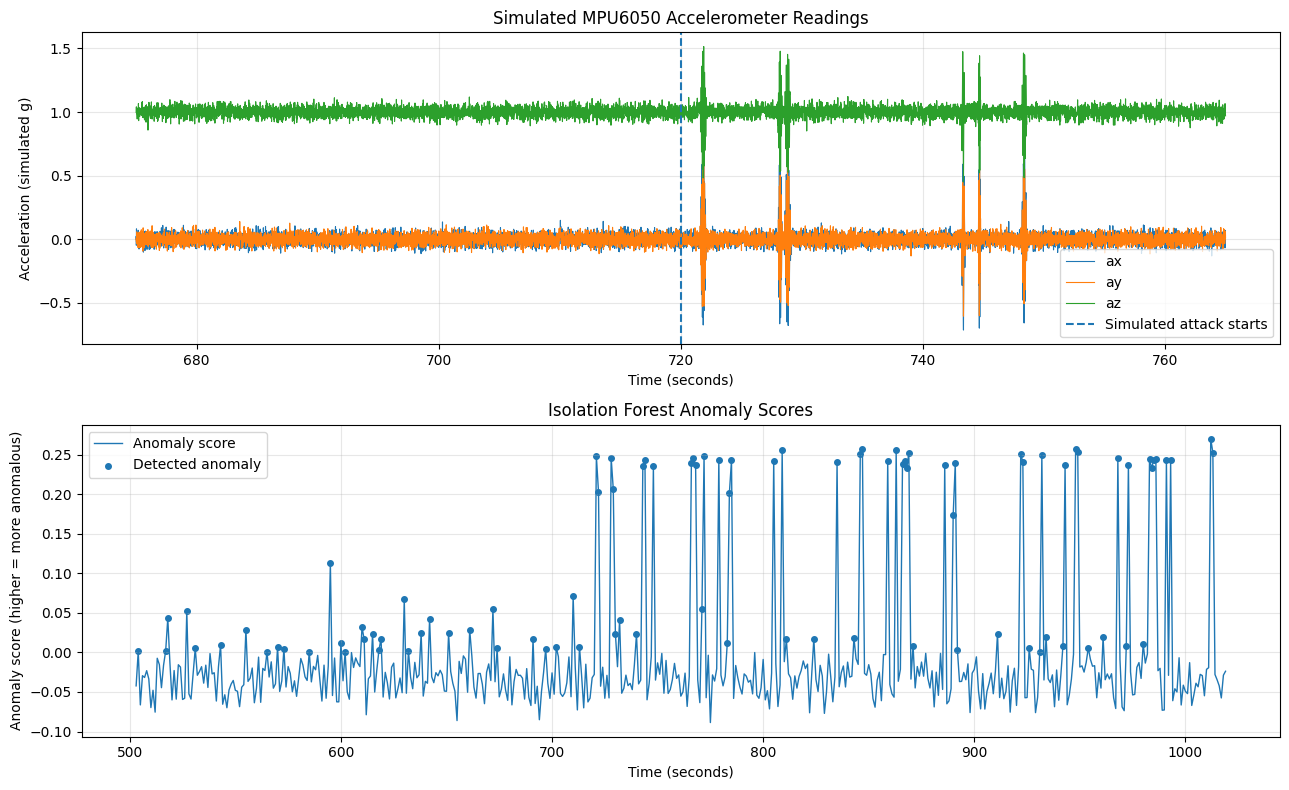

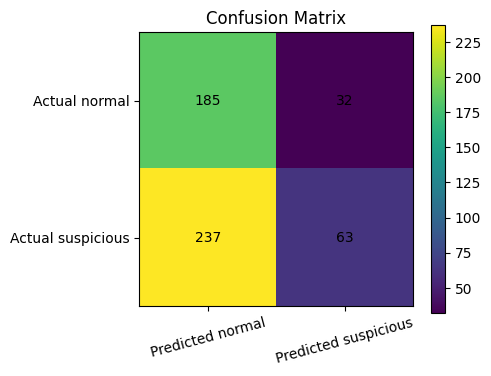

In [ ]:
# 6. Visualizations for your demonstration video
fig, axes = plt.subplots(2, 1, figsize=(13, 8))

# Raw sample stream: show a short slice around the transition
show_seconds = 90
raw_show = raw_df[(raw_df.timestamp_s >= SECONDS_NORMAL - 45) &
                  (raw_df.timestamp_s <= SECONDS_NORMAL + 45)]
axes[0].plot(raw_show["timestamp_s"], raw_show["ax"], linewidth=0.8, label="ax")
axes[0].plot(raw_show["timestamp_s"], raw_show["ay"], linewidth=0.8, label="ay")
axes[0].plot(raw_show["timestamp_s"], raw_show["az"], linewidth=0.8, label="az")
axes[0].axvline(SECONDS_NORMAL, linestyle="--", label="Simulated attack starts")
axes[0].set_title("Simulated MPU6050 Accelerometer Readings")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Acceleration (simulated g)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

plot_df = test_df.sort_values("timestamp_s")
axes[1].plot(plot_df["timestamp_s"], plot_df["anomaly_score"], linewidth=1, label="Anomaly score")
axes[1].scatter(plot_df.loc[plot_df.predicted_label == 1, "timestamp_s"],
                plot_df.loc[plot_df.predicted_label == 1, "anomaly_score"],
                s=16, label="Detected anomaly")
axes[1].set_title("Isolation Forest Anomaly Scores")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Anomaly score (higher = more anomalous)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 4))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.xticks([0, 1], ["Predicted normal", "Predicted suspicious"], rotation=15)
plt.yticks([0, 1], ["Actual normal", "Actual suspicious"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")
plt.colorbar()
plt.tight_layout()
plt.show()


In [ ]:
# 7. Security alert log — display recent simulated detections
alerts = test_df[test_df["predicted_label"] == 1].copy()
alerts["alert_type"] = "POTENTIAL PHYSICAL TAMPER"
alerts["alert_message"] = alerts["activity"].map({
    "normal": "Unusual sensor pattern — review required",
    "shaking": "High vibration pattern detected — inspect ATM",
    "hitting": "Impact-like pattern detected — inspect ATM",
    "prying": "Irregular movement pattern detected — inspect ATM",
    "drilling": "High-frequency vibration pattern detected — inspect ATM"
}).fillna("Anomalous sensor pattern detected — inspect ATM")
alerts["timestamp_hms"] = alerts["timestamp_s"].map(
    lambda x: f"{int(x//3600):02d}:{int((x%3600)//60):02d}:{int(x%60):02d}"
)

print(f"Potential anomaly alerts generated: {len(alerts):,}")
if len(alerts):
    display(alerts[["timestamp_hms", "alert_type", "alert_message", "anomaly_score"]]
            .head(25).round(4))
else:
    print("No anomalies detected in this test run.")
print("\nDEMO ALERT: This is a simulated alert generated from synthetic sensor data.")


Potential anomaly alerts generated: 95


,timestamp_hms,alert_type,alert_message,anomaly_score
1,00:08:24,POTENTIAL PHYSICAL TAMPER,Unusual sensor pattern — review required,0.0013
14,00:08:37,POTENTIAL PHYSICAL TAMPER,Unusual sensor pattern — review required,0.0021
15,00:08:38,POTENTIAL PHYSICAL TAMPER,Unusual sensor pattern — review required,0.0430
24,00:08:47,POTENTIAL PHYSICAL TAMPER,Unusual sensor pattern — review required,0.0523
28,00:08:51,POTENTIAL PHYSICAL TAMPER,Unusual sensor pattern — review required,0.0050
40,00:09:03,POTENTIAL PHYSICAL TAMPER,Unusual sensor pattern — review required,0.0095
52,00:09:15,POTENTIAL PHYSICAL TAMPER,Unusual sensor pattern — review required,0.0287
62,00:09:25,POTENTIAL PHYSICAL TAMPER,Unusual sensor pattern — review required,0.0008
67,00:09:30,POTENTIAL PHYSICAL TAMPER,Unusual sensor pattern — review required,0.0069
70,00:09:33,POTENTIAL PHYSICAL TAMPER,Unusual sensor pattern — review required,0.0044



DEMO ALERT: This is a simulated alert generated from synthetic sensor data.


In [ ]:
# 8. Export outputs for your report/video evidence
raw_df.to_csv("simulated_atm_sensor_data.csv", index=False)
features_df.to_csv("atm_window_features.csv", index=False)
test_df.to_csv("atm_anomaly_predictions.csv", index=False)
metrics_df.to_csv("atm_model_metrics.csv", index=False)
alerts.to_csv("atm_security_alerts.csv", index=False)

print("Saved output CSV files:")
for filename in [
    "simulated_atm_sensor_data.csv",
    "atm_window_features.csv",
    "atm_anomaly_predictions.csv",
    "atm_model_metrics.csv",
    "atm_security_alerts.csv"
]:
    print(" •", filename)

print("\nDemo complete. For your video, show the generated raw data, feature table,")
print("model training output, metrics, anomaly plots, and alert log.")


Saved output CSV files:
 • simulated_atm_sensor_data.csv
 • atm_window_features.csv
 • atm_anomaly_predictions.csv
 • atm_model_metrics.csv
 • atm_security_alerts.csv

Demo complete. For your video, show the generated raw data, feature table,
model training output, metrics, anomaly plots, and alert log.


In [ ]:
import zipfile
from google.colab import files

csv_files = [
    "simulated_atm_sensor_data.csv",
    "atm_window_features.csv",
    "atm_anomaly_predictions.csv",
    "atm_model_metrics.csv",
    "atm_security_alerts.csv"
]

zip_name = "Smart_ATM_Project_Outputs.zip"

with zipfile.ZipFile(zip_name, "w") as z:
    for filename in csv_files:
        z.write(filename)

files.download(zip_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>